# 04 — Routing layer (OpenStreetMap road graph + networkx)

OpenStreetMap supplies the road network; **networkx** computes routes. No `osmnx`/`geopandas` dependency,
because that geospatial stack is painful to install on s390x.

* The graph is downloaded **once** from the Overpass API and cached as plain JSON in `data/road_graph.json`.
  Copy that file to LinuxONE so the demo needs no internet access. If the download fails, a synthetic grid is used.
* Hazards are circles (centre, radius, severity). Each edge gets a `hazard` intensity in 0–1; edges above
  `BLOCK_THRESHOLD` are treated as impassable.
* *Fastest route* ignores hazards; *safest route* penalises hazard exposure and avoids blocked edges.

Notebook 05 loads this notebook with `%run` and reuses the functions (set `RUN_ROUTING_DEMO = False` first).

In [1]:
from pathlib import Path

# Works both when Jupyter is started in the repo root and inside notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
ART = ROOT / "artifacts"
DATA.mkdir(exist_ok=True)
ART.mkdir(exist_ok=True)

import json
import math
import numpy as np
import networkx as nx
import requests
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.patches import Ellipse

GRAPH_PATH = DATA / "road_graph.json"
RUN_ROUTING_DEMO = globals().get("RUN_ROUTING_DEMO", True)

# Area of interest as (south, west, north, east). Default: south of Valencia, Spain (2024 DANA floods).
# Change it, then delete data/road_graph.json to re-download.
BBOX = (39.40, -0.45, 39.48, -0.35)
USE_OSM = True
OVERPASS_URLS = ["https://overpass-api.de/api/interpreter",
                 "https://overpass.kumi.systems/api/interpreter",
                 "https://maps.mail.ru/osm/tools/overpass/api/interpreter"]

DEFAULT_SPEED_KMH = {"motorway": 100, "trunk": 80, "primary": 60, "secondary": 50, "tertiary": 40,
                     "unclassified": 30}
BLOCK_THRESHOLD = 0.6     # edge hazard at/above this is treated as impassable
HAZARD_PENALTY = 20.0     # safest route: cost = travel_min * (1 + HAZARD_PENALTY * hazard)
MAX_HAZARD_DISTANCE_KM = 50.0

## Graph construction, caching and loading

In [2]:
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371.0 * 2 * np.arcsin(np.sqrt(a))


def add_road(G, u, v, speed_kmh, highway=""):
    length = float(haversine_km(G.nodes[u]["lat"], G.nodes[u]["lon"], G.nodes[v]["lat"], G.nodes[v]["lon"]))
    G.add_edge(u, v, length_km=length, speed_kmh=speed_kmh, travel_min=60 * length / speed_kmh,
               highway=highway, hazard=0.0)


def parse_speed(maxspeed, highway):
    base = highway.replace("_link", "")
    try:
        return float(str(maxspeed).split()[0])
    except (TypeError, ValueError):
        return float(DEFAULT_SPEED_KMH.get(base, 30))


def fetch_osm_graph(bbox):
    s, w, n, e = bbox
    query = f"""
    [out:json][timeout:90];
    way["highway"~"^(motorway|trunk|primary|secondary|tertiary|unclassified)(_link)?$"]({s},{w},{n},{e});
    (._;>;);
    out body;
    """
    errors = []
    for url in OVERPASS_URLS:     # public servers are often busy; try mirrors in turn
        try:
            resp = requests.post(url, data={"data": query},
                                 headers={"User-Agent": "ReliefSyncZ-prototype/0.1"}, timeout=120)
            resp.raise_for_status()
            elements = resp.json()["elements"]
            break
        except Exception as exc:
            errors.append(f"{url}: {exc}")
    else:
        raise RuntimeError("; ".join(errors))

    G = nx.Graph(source=f"OpenStreetMap bbox={bbox}")
    for el in elements:
        if el["type"] == "node":
            G.add_node(el["id"], lat=el["lat"], lon=el["lon"])
    for el in elements:
        if el["type"] != "way":
            continue
        tags = el.get("tags", {})
        speed = parse_speed(tags.get("maxspeed"), tags.get("highway", ""))
        for u, v in zip(el["nodes"][:-1], el["nodes"][1:]):
            if u in G and v in G and u != v:
                add_road(G, u, v, speed, tags.get("highway", ""))
    largest = max(nx.connected_components(G), key=len)
    return G.subgraph(largest).copy()


def build_synthetic_grid(n=20, lat0=39.40, lon0=-0.45, step=0.004):
    G = nx.Graph(source="synthetic grid")
    for i in range(n):
        for j in range(n):
            G.add_node(i * n + j, lat=lat0 + i * step, lon=lon0 + j * step)
    for i in range(n):
        for j in range(n):
            if j + 1 < n:
                add_road(G, i * n + j, i * n + j + 1, 80 if i % 5 == 0 else 50, "synthetic")
            if i + 1 < n:
                add_road(G, i * n + j, (i + 1) * n + j, 80 if j % 5 == 0 else 50, "synthetic")
    return G


def save_graph(G, path):
    payload = {
        "source": G.graph.get("source", ""),
        "nodes": [[n, d["lat"], d["lon"]] for n, d in G.nodes(data=True)],
        "edges": [[u, v, d["speed_kmh"], d["highway"]] for u, v, d in G.edges(data=True)],
    }
    path.write_text(json.dumps(payload))


def load_graph(path):
    payload = json.loads(path.read_text())
    G = nx.Graph(source=payload["source"])
    for n, lat, lon in payload["nodes"]:
        G.add_node(n, lat=lat, lon=lon)
    for u, v, speed, highway in payload["edges"]:
        add_road(G, u, v, speed, highway)
    return G


def get_graph():
    if GRAPH_PATH.exists():
        return load_graph(GRAPH_PATH)
    G = None
    if USE_OSM:
        try:
            G = fetch_osm_graph(BBOX)
        except Exception as exc:
            print(f"OSM download failed ({exc}); using a synthetic grid instead")
    if G is None:
        G = build_synthetic_grid()
    save_graph(G, GRAPH_PATH)
    return G


G = get_graph()
print(f"{G.graph['source']}: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

OpenStreetMap bbox=(39.4, -0.45, 39.48, -0.35): 19265 nodes, 20301 edges


## Hazards and routing

In [3]:
def make_hazard(lat, lon, radius_km=1.0, severity=0.9, kind="FLOOD"):
    return {"lat": float(lat), "lon": float(lon), "radius_km": radius_km, "severity": severity, "kind": kind}


def apply_hazards(G, hazards):
    """Sets each edge's hazard intensity (0-1) from the active hazards."""
    for u, v, d in G.edges(data=True):
        lat = (G.nodes[u]["lat"] + G.nodes[v]["lat"]) / 2
        lon = (G.nodes[u]["lon"] + G.nodes[v]["lon"]) / 2
        d["hazard"] = max((hz["severity"] * math.exp(-(float(haversine_km(lat, lon, hz["lat"], hz["lon"]))
                                                       / hz["radius_km"]) ** 2) for hz in hazards), default=0.0)


def fastest_route(G, source, target):
    return nx.shortest_path(G, source, target, weight="travel_min")


def safest_route(G, source, target):
    def cost(u, v, d):
        if d["hazard"] >= BLOCK_THRESHOLD:
            return None    # networkx skips edges whose weight is None
        return d["travel_min"] * (1 + HAZARD_PENALTY * d["hazard"])
    try:
        return nx.shortest_path(G, source, target, weight=cost)
    except nx.NetworkXNoPath:
        return None


def route_metrics(G, path, hazards=()):
    edges = list(zip(path[:-1], path[1:]))
    exposure = max((G[u][v]["hazard"] for u, v in edges), default=0.0)
    distance = MAX_HAZARD_DISTANCE_KM
    if hazards:
        lats = np.array([G.nodes[n]["lat"] for n in path])
        lons = np.array([G.nodes[n]["lon"] for n in path])
        distance = min(float(haversine_km(lats, lons, hz["lat"], hz["lon"]).min()) for hz in hazards)
    return {
        "travel_min": sum(G[u][v]["travel_min"] for u, v in edges),
        "length_km": sum(G[u][v]["length_km"] for u, v in edges),
        "hazard_exposure": exposure,
        "blocked": exposure >= BLOCK_THRESHOLD,
        "min_distance_to_hazard_km": min(distance, MAX_HAZARD_DISTANCE_KM),
    }


def pick_endpoints(G):
    """Placeholder depot/destination/backup hub: three opposite corners of the map."""
    nodes = list(G.nodes)
    lat = np.array([G.nodes[n]["lat"] for n in nodes])
    lon = np.array([G.nodes[n]["lon"] for n in nodes])
    return nodes[int(np.argmin(lat + lon))], nodes[int(np.argmax(lat + lon))], nodes[int(np.argmax(lat - lon))]


def plot_network(G, routes=None, hazards=(), ax=None, title=""):
    ax = ax or plt.subplots(figsize=(8, 8))[1]
    segments = [[(G.nodes[u]["lon"], G.nodes[u]["lat"]), (G.nodes[v]["lon"], G.nodes[v]["lat"])] for u, v in G.edges]
    ax.add_collection(LineCollection(segments, colors="#c8c8c8", linewidths=0.6))
    for label, (path, color) in (routes or {}).items():
        if path:
            ax.plot([G.nodes[n]["lon"] for n in path], [G.nodes[n]["lat"] for n in path], color=color, lw=3,
                    label=label)
    for hz in hazards:
        r_lat = hz["radius_km"] / 110.57
        r_lon = hz["radius_km"] / (111.32 * math.cos(math.radians(hz["lat"])))
        ax.add_patch(Ellipse((hz["lon"], hz["lat"]), 2 * r_lon, 2 * r_lat, color="tab:blue", alpha=0.3,
                             label=f"{hz['kind']} hazard"))
    ax.autoscale()
    ax.set_aspect(1 / math.cos(math.radians(np.mean([d["lat"] for _, d in G.nodes(data=True)]))))
    ax.set_title(title)
    if G.graph.get("source", "").startswith("OpenStreetMap"):
        ax.text(0.01, 0.01, "Map data © OpenStreetMap contributors (ODbL)", transform=ax.transAxes, fontsize=8,
                color="#555555")
    if routes or hazards:
        ax.legend(loc="lower right")
    return ax

## Demo: inject a flood on the fastest route and find a safer alternative

baseline {'travel_min': 19.215, 'length_km': 15.28, 'hazard_exposure': 0.9, 'blocked': 1.0, 'min_distance_to_hazard_km': 0.0}
alternative {'travel_min': 19.925, 'length_km': 18.402, 'hazard_exposure': 0.042, 'blocked': 0.0, 'min_distance_to_hazard_km': 1.748}


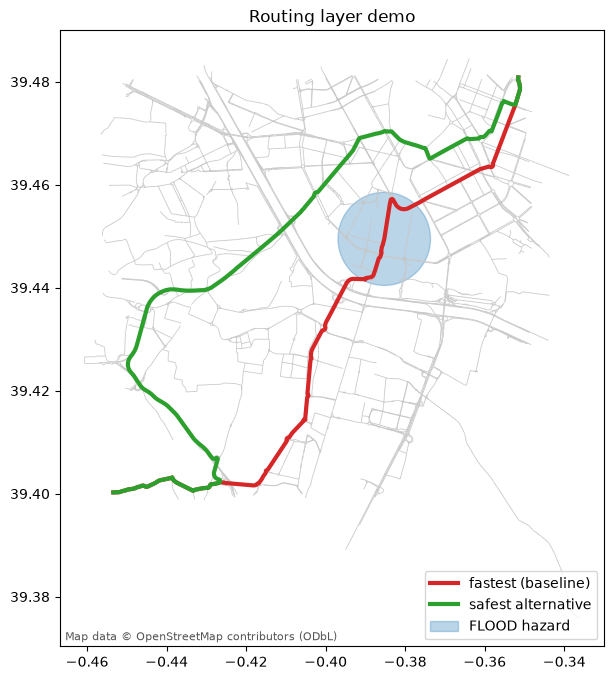

In [4]:
if RUN_ROUTING_DEMO:
    origin, destination, hub = pick_endpoints(G)
    baseline = fastest_route(G, origin, destination)
    mid = baseline[int(len(baseline) * 0.6)]
    hazards = [make_hazard(G.nodes[mid]["lat"], G.nodes[mid]["lon"], radius_km=1.0, severity=0.9)]
    apply_hazards(G, hazards)
    alternative = safest_route(G, origin, destination)

    for name, path in [("baseline", baseline), ("alternative", alternative)]:
        m = route_metrics(G, path, hazards) if path else None
        print(name, {k: round(float(v), 3) for k, v in m.items()} if m else "no route")

    plot_network(G, {"fastest (baseline)": (baseline, "tab:red"), "safest alternative": (alternative, "tab:green")},
                 hazards, title="Routing layer demo")
    apply_hazards(G, [])   # reset